# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [2]:
STUDENT_NAME = 'Іванів Христина'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 4      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам’янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 4: Одеса, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [3]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [4]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [5]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_одеса


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [42]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 1, відповідають 1 ['162.55.144.139']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [43]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- живий запит -----
    t0, b0 = time.time(), cache_bytes()          # 1) стан ДО запиту
    g = getter()                                  # 2) запит (або читання сирого файлу OSM)
    clean(g).to_parquet(path, index=False)        #    зберегти знімок
    g = gpd.read_parquet(path)                    #    повернути те саме, що читатиметься потім
    COST[name] = {'спосіб': 'живий запит',        # 3) облік
                  'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [44]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 163.3 км²


In [45]:
# Основний сервер overpass-api.de відхиляє автоматизовані запити, а дзеркала
# не відповідали. Тому сирі дані завантажено вручну через Overpass Turbo
# (браузер) у форматі OSM XML з тими самими фільтрами тегів, а osmnx читає файли.
OSM_FEAT = 'odesa_features.osm'
OSM_WALK = 'odesa_walk.osm'
assert os.path.exists(OSM_FEAT) and os.path.exists(OSM_WALK), 'покладіть обидва .osm поруч із зошитом'

heritage = fetch('heritage', lambda: ox.features_from_xml(
    OSM_FEAT, polygon=poly, tags={'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_xml(
    OSM_FEAT, polygon=poly, tags={'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_xml(
    OSM_FEAT, polygon=poly, tags={'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P) + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0 = time.time()
    # bidirectional=True: пішоходу односторонній рух не заважає (так робить і osmnx для 'walk')
    # simplify=False: лишаємо проміжні вузли вздовж вулиць,
    # інакше сусідні пам'ятки прилипають до одного перехрестя
    G_raw = ox.graph_from_xml(OSM_WALK, bidirectional=True, simplify=False, retain_all=True)
    G_raw = ox.truncate.truncate_graph_polygon(G_raw, poly)       # лише в межах міста
    G_raw = ox.truncate.largest_component(G_raw, strongly=False)  # без відірваних шматків
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'файл OSM XML', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round(os.path.getsize(OSM_WALK) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P) + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

# три шари пам'яток прийшли одним файлом — позначаємо це в таблиці
for k in ['heritage', 'stations', 'amenities']:
    if COST[k]['спосіб'] == 'живий запит':
        COST[k]['спосіб'] = 'файл OSM XML'
if COST['heritage']['спосіб'] == 'файл OSM XML':
    COST['heritage']['передано_МБ'] = round(os.path.getsize(OSM_FEAT) / 1e6, 3)

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 73011 | ребер 167262


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [1]:
display(pd.DataFrame(COST).T)

NameError: name 'pd' is not defined

> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [47]:
has_hist = heritage['historic'].notna()
has_tour = heritage['tourism'].isin(TOURISM_OK)
mask = has_hist | has_tour                                  # об'єднання двох сімейств

has_name = heritage['name'].notna() & (heritage['name'].str.strip() != '')
cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('  лише historic        :', int((has_hist & ~has_tour).sum()))
print('  лише tourism         :', int((has_tour & ~has_hist).sum()))
print('  обидва               :', int((has_hist & has_tour).sum()))
print('з них мають name       :', len(cand))

# що саме відкинуто через відсутність назви
dropped = heritage[mask & ~has_name]
kind = dropped['historic'].fillna('tourism=' + dropped['tourism'].fillna('?'))
print('\nвідкинуто без назви:', len(dropped))
print(kind.value_counts().head(10).to_string())
print('типи геометрії відкинутих:', dropped.geometry.geom_type.value_counts().to_dict())

усього у шарі heritage : 895
підходять за тегами    : 895
  лише historic        : 588
  лише tourism         : 289
  обидва               : 18
з них мають name       : 547

відкинуто без назви: 348
historic
heritage              163
memorial               74
tourism=artwork        56
tourism=attraction     36
tourism=viewpoint       6
yes                     3
fort                    3
castle                  2
bicycle                 2
monument                2
типи геометрії відкинутих: {'Polygon': 207, 'Point': 140, 'MultiPolygon': 1}


In [48]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial     189
heritage     120
monument      19
cannon         6
synagogue      4
castle         4
yes            4
building       2
tank           1
aircraft       1

=== tourism ===
tourism
artwork       84
attraction    72
museum        42
viewpoint      5
gallery        5

типи геометрії: {'Point': 343, 'Polygon': 199, 'LineString': 5}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [49]:
# ── 0. площа ──
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# ── 1. сигнали ──
wiki_cols = [c for c in ['wikidata', 'wikipedia'] if c in cand.columns]
cand['wiki'] = cand[wiki_cols].notna().any(axis=1).astype(int) if wiki_cols else 0

lang_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)

cand['visit'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['hist'] = cand['historic'].notna().astype(int)

# ── 2. зведення до спільної шкали 0..1 ──
r_lang = cand['n_lang'].rank(pct=True)
r_area = cand['area_m2'].rank(pct=True)

# ── 3. зважена сума ──
W = {'wiki': 0.40, 'n_lang': 0.25, 'visit': 0.15, 'hist': 0.10, 'area': 0.10}
cand['score'] = (W['wiki'] * cand['wiki'] + W['n_lang'] * r_lang +
                 W['visit'] * cand['visit'] + W['hist'] * cand['hist'] +
                 W['area'] * r_area)

print('кандидатів    :', len(cand))
print('мають wiki    :', int(cand['wiki'].sum()))
print('колонок name:*:', len(lang_cols), '| мають ≥1 переклад:', int((cand['n_lang'] > 0).sum()))
print('музеїв/галерей:', int(cand['visit'].sum()))
display(cand.nlargest(15, 'score')[['name', 'historic', 'tourism', 'wiki', 'n_lang', 'area_m2', 'score']]
        .round({'area_m2': 0, 'score': 3}))

кандидатів    : 547
мають wiki    : 47
колонок name:*: 16 | мають ≥1 переклад: 533
музеїв/галерей: 47


,name,historic,tourism,wiki,n_lang,area_m2,score
364,Літературний музей,NaN,museum,1,5,1382.0,0.891
363,Археологічний музей,NaN,museum,1,6,1015.0,0.890
515,Одеський національний художній музей,NaN,museum,1,3,1608.0,0.872
348,Потьомкінські сходи,yes,attraction,1,9,2825.0,0.848
511,Одеський залізничний вокзал,heritage,attraction,1,5,4826.0,0.847
544,Воронцовський палац,castle,NaN,1,4,1404.0,0.838
353,Синагога Ор Самеах,synagogue,attraction,1,4,1147.0,0.835
421,Одеський академічний театр музичної комедії ім...,monument,NaN,1,3,4975.0,0.826
486,Прибутковий будинок Асвадурова,heritage,NaN,1,3,1959.0,0.823
423,Римсько-католицький костьол Успіння Пресвятої ...,church,NaN,1,3,1449.0,0.821


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [50]:
N_SMALL, N_LARGE = 10, 30

top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)

overlap = len(set(top10['name']) & set(top_naive['name']))
print('перетин: %d з %d' % (overlap, N_SMALL))

display(pd.DataFrame({
    'за вашим критерієм': list(top10['name']),
    'за площею':          list(top_naive['name']),
    'площа, м²':          top_naive['area_m2'].round(0).astype(int).values,
    'тег (за площею)':    top_naive['historic'].fillna(top_naive['tourism']).values,
}))

перетин: 2 з 10


,за вашим критерієм,за площею,"площа, м²",тег (за площею)
0,Літературний музей,Свято-успенський патріарший чоловічий монастир...,58315,attraction
1,Археологічний музей,Ангари,10129,heritage
2,Одеський національний художній музей,Гарматні дворики,8277,memorial
3,Потьомкінські сходи,Одеський художній музей,5288,gallery
4,Одеський залізничний вокзал,Одеський академічний театр музичної комедії ім...,4975,monument
5,Воронцовський палац,Одеський залізничний вокзал,4826,heritage
6,Синагога Ор Самеах,Одеський національний академічний театр опери ...,4720,attraction
7,Одеський академічний театр музичної комедії ім...,Ангари депо,4251,heritage
8,Прибутковий будинок Асвадурова,Пасаж Менделевичів,3647,attraction
9,Римсько-католицький костьол Успіння Пресвятої ...,Тюремний замок,3209,monument


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [51]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# 1) вокзал — це старт маршруту, а не пам'ятка, яку треба «відвідати»
is_station = cand['name'].str.contains('вокзал', case=False, na=False)
print('прибираємо як старт:', list(cand.loc[is_station, 'name']))

# 2) шукаємо близькі пари в перших 30 (після вилучення вокзалу)
top_score = cand[~is_station].nlargest(N_LARGE, 'score').reset_index(drop=True)
pairs = close_pairs(top_score, 60)
print('\nпар ближче 60 м:', len(pairs))

def _tag(r):
    return r['tourism'] if pd.notna(r['tourism']) else r['historic']

for i, j, d in pairs:
    a, b = top_score.loc[i], top_score.loc[j]
    print('%5.1f м | %-45s (score %.3f, %s) | %-45s (score %.3f, %s)' % (
        d, a['name'][:45], a['score'], _tag(a), b['name'][:45], b['score'], _tag(b)))

прибираємо як старт: ['Одеський залізничний вокзал']

пар ближче 60 м: 5
 21.2 м | Одеський національний художній музей          (score 0.872, museum) | Одеський художній музей                       (score 0.803, gallery)
 22.4 м | Одеський художній музей                       (score 0.803, gallery) | Пам'ятник засновникам Одеси (демонтований)    (score 0.781, memorial)
 25.8 м | Одеський національний художній музей          (score 0.872, museum) | Пам'ятник засновникам Одеси (демонтований)    (score 0.781, memorial)
 42.3 м | Будинок О. П. Руссова                         (score 0.744, heritage) | Будинок Лібмана                               (score 0.740, heritage)
 54.9 м | Літературний музей                            (score 0.891, museum) | Археологічний музей                           (score 0.890, museum)


In [52]:
# рішення щодо дублікатів
DROP = [
    'Одеський художній музей',                      # дубль «Одеського національного художнього музею» (gallery vs museum)
    "Пам'ятник засновникам Одеси (демонтований)",   # демонтований, перенесений на територію музею
]
drop_mask = cand['name'].isin(DROP) | is_station
print('вилучаємо:', list(cand.loc[drop_mask, 'name']))

cand_final = cand[~drop_mask].reset_index(drop=True)
top_score = cand_final.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)

print('\nпісля очищення пар ближче 60 м:')
for i, j, d in close_pairs(top_score, 60):
    print('  %5.1f м | %s | %s' % (d, top_score.loc[i, 'name'], top_score.loc[j, 'name']))

print('\nфінальна десятка:')
for k, nm in enumerate(top10['name'], 1):
    print('  %2d. %s' % (k, nm))

вилучаємо: ["Пам'ятник засновникам Одеси (демонтований)", 'Одеський залізничний вокзал', 'Одеський художній музей']

після очищення пар ближче 60 м:
   42.3 м | Будинок О. П. Руссова | Будинок Лібмана
   54.9 м | Літературний музей | Археологічний музей

фінальна десятка:
   1. Літературний музей
   2. Археологічний музей
   3. Одеський національний художній музей
   4. Потьомкінські сходи
   5. Воронцовський палац
   6. Синагога Ор Самеах
   7. Одеський академічний театр музичної комедії імені Михайла Водяного
   8. Прибутковий будинок Асвадурова
   9. Римсько-католицький костьол Успіння Пресвятої Богородиці Діви Марії
  10. Шахський палац


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [53]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 26
                   name  railway building
0         Одеса-Західна  station      NaN
1          Одеса-Поїзна  station      NaN
2       Одеса-Застава 2  station      NaN
3              Шевченко     halt      NaN
4     Одеса-Сортувальна  station      NaN
5                  Депо     halt      NaN
6         Одеса-Пересип  station      NaN
7           Житомирська  station      NaN
8            Одеса-Порт  station      NaN
9       Одеса-Застава I  station      NaN
10           Слобідська     halt      NaN
11  Дальницький Переїзд     halt      NaN


In [54]:
named = stations[stations['name'].notna()].copy()
pick = named[named['name'].str.contains('Одеса-Головна|Головна|вокзал', case=False, regex=True)]
print('кандидати на старт:')
print(pick[['name', 'railway', 'building']].to_string())

# перевага — об'єкт railway=station (сама станція); якщо нема — будівля вокзалу
pick = pick.assign(_pri=(pick['railway'] != 'station').astype(int)).sort_values('_pri')
station = pick.head(1).drop(columns='_pri')
print('\nстарт:', station['name'].iloc[0])

кандидати на старт:
                           name  railway       building
13                Одеса-Головна  station            NaN
24  Одеський залізничний вокзал      NaN  train_station

старт: Одеса-Головна


In [55]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 73011 вузлів, 167258 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [56]:
def check_snap(points, ids, dist, label):
    n_pts = len(ids)
    n_nodes = len(set(ids))
    print('=== %s ===' % label)
    print('точок: %d | різних вузлів: %d' % (n_pts, n_nodes))
    print('відстань точка → вузол: медіана %.1f м, максимум %.1f м (%s)'
          % (np.median(dist), dist.max(), points['name'].iloc[int(np.argmax(dist))]))

    if n_nodes < n_pts:
        print('УВАГА: точки злиплись на одному вузлі:')
        for node, cnt in collections.Counter(ids).items():
            if cnt > 1:
                names = [points['name'].iloc[k] for k in range(n_pts) if ids[k] == node]
                print('   вузол %s ← %s' % (node, ' | '.join(names)))
    else:
        print('OK: кожна точка має власний вузол')
    print()

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [57]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    """Пряма (евклідова) віддаль між точками в метрах."""
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    """Медіана відношення «дорогою / по прямій» по всіх скінченних парах i≠j."""
    k = len(D)
    off = ~np.eye(k, dtype=bool)
    ok = off & np.isfinite(D) & (E > 0)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [58]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

=== мала задача ===
точок: 11 | різних вузлів: 11
відстань точка → вузол: медіана 29.3 м, максимум 34.6 м (Одеський академічний театр музичної комедії імені Михайла Водяного)
OK: кожна точка має власний вузол

матриця за 1.793 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.22


> **Асиметрія.** $D_{ij} \neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [65]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    tour = [0]
    unvisited = set(range(1, k))
    while unvisited:
        cur = tour[-1]
        nxt = min(unvisited, key=lambda j: D[cur, j])   # найближча з невідвіданих
        tour.append(nxt)
        unvisited.remove(nxt)
    tour.append(0)                                      # повернення на старт
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):               # старт (0) і фініш не чіпаємо
            for j in range(i + 1, len(best) - 1):
                cand = best[:i] + best[i:j + 1][::-1] + best[j + 1:]   # розвернути ділянку i..j
                cand_len = tour_length(D, cand)
                if cand_len < best_len - 1e-9:
                    best, best_len = cand, cand_len
                    improved = True
    return best

In [66]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [67]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв’язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [68]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,10439,7.54
2-opt,9833,1.30
Held-Karp (точний),9707,0.00



оптимальний порядок:
   0. СТАРТ: Одеса-Головна
   1. Прибутковий будинок Асвадурова
   2. Синагога Ор Самеах
   3. Римсько-католицький костьол Успіння Пресвятої Богородиці Діви Марії
   4. Одеський національний художній музей
   5. Шахський палац
   6. Воронцовський палац
   7. Потьомкінські сходи
   8. Археологічний музей
   9. Літературний музей
  10. Одеський академічний театр музичної комедії імені Михайла Водяного
  11. СТАРТ: Одеса-Головна

довжина: 9.71 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [71]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)          # розмір таблиці dp у Held-Karp
    gb = cells * 8 / 1e9                     # 8 байтів на клітинку (float64)
    ops = 2 ** (n - 1) * (n - 1) ** 2        # порядок кількості операцій O(2^n · n²)
    rows.append({'n (точок з вокзалом)': n,
                 'клітин таблиці': f'{cells:,}'.replace(',', ' '),
                 'пам\'ять, ГБ': round(gb, 3),
                 'операцій': f'{ops:.1e}'})
display(pd.DataFrame(rows).set_index('n (точок з вокзалом)'))


,клітин таблиці,"пам'ять, ГБ",операцій
n (точок з вокзалом),,,
11,10 240,0.000,1.0e+05
16,491 520,0.004,7.4e+06
21,20 971 520,0.168,4.2e+08
26,838 860 800,6.711,2.1e+10
31,32 212 254 720,257.698,9.7e+11


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [72]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

=== велика задача ===
точок: 31 | різних вузлів: 31
відстань точка → вузол: медіана 22.5 м, максимум 46.6 м (Свято-Успенський кафедральний собор УПЦ МП)
OK: кожна точка має власний вузол

коефіцієнт обходу: 1.26
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    27937 м
2-opt            :    23493 м  за 0.010 с  (коротше на 15.9%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

In [75]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# 1) кожного кандидата — у комірку H3
rp = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rp]

# 2) щільність: скільки пам'яток у кожній комірці
dens = cand.groupby('h3').size().rename('n').reset_index()

# 3) шестикутники як полігони: h3 дає (lat, lng), shapely чекає (lng, lat) — міняємо місцями
hexes = gpd.GeoDataFrame(
    dens,
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens['h3']],
    crs='EPSG:4326')

# 4) у скількох комірках половина всіх пам'яток
s = dens['n'].sort_values(ascending=False).reset_index(drop=True)
share = s.cumsum() / s.sum()
half = int((share < 0.5).sum()) + 1
print('кандидатів: %d | непорожніх комірок: %d' % (len(cand), len(dens)))
print('половина пам\'яток — у %d комірках (%.1f%% непорожніх)' % (half, 100 * half / len(dens)))
print('найщільніші комірки:', s.head(5).tolist())



середнє ребро комірки: 201 м
середнє ребро комірки: 201 м
кандидатів: 547 | непорожніх комірок: 219
половина пам'яток — у 34 комірках (15.5% непорожніх)
найщільніші комірки: [24, 23, 16, 14, 14]


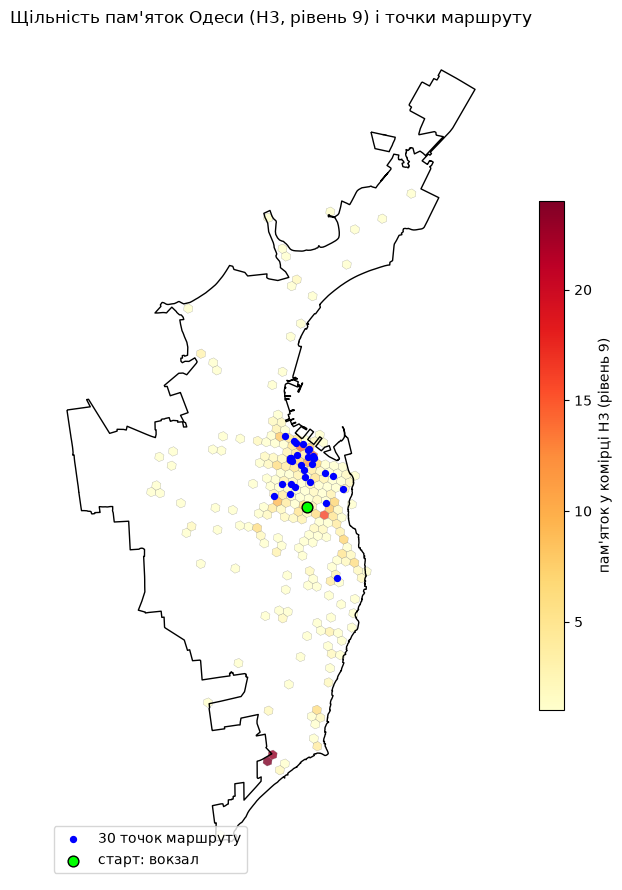

In [76]:
fig, ax = plt.subplots(figsize=(9, 9))
boundary.boundary.plot(ax=ax, color='black', linewidth=1)
hexes.plot(ax=ax, column='n', cmap='YlOrRd', legend=True, alpha=0.8,
           edgecolor='grey', linewidth=0.2,
           legend_kwds={'label': "пам'яток у комірці H3 (рівень 9)", 'shrink': 0.6})
pts30.plot(ax=ax, color='blue', markersize=18, label='30 точок маршруту', zorder=3)
pts30.iloc[[0]].plot(ax=ax, color='lime', markersize=60, edgecolor='black', label='старт: вокзал', zorder=4)
ax.set_title('Щільність пам\'яток Одеси (H3, рівень 9) і точки маршруту')
ax.legend(loc='lower left'); ax.set_axis_off()
plt.tight_layout(); plt.show()

hmap.save('lr5_h3.html')   # інтерактивну версію можна відкрити в браузері

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [77]:
# обидва шари — у метричну проєкцію, інакше відстань буде в градусах
amen = amenities[['name', 'amenity', 'geometry']].copy()
amen['geometry'] = amen.geometry.representative_point()      # кафе-полігон → точка
amen_m = amen.to_crs(32635)
route_m = pts10.to_crs(32635)

near = gpd.sjoin_nearest(route_m, amen_m, how='left', distance_col='відстань_м',
                         lsuffix='точка', rsuffix='заклад')
near = near[~near.index.duplicated()]        # якщо два заклади на однаковій відстані — беремо один

tab8 = pd.DataFrame({
    'точка маршруту':     near['name_точка'].values,
    'найближчий заклад':  near['name_заклад'].fillna('(без назви)').values,
    'тип':                near['amenity'].values,
    'відстань, м':        near['відстань_м'].round(0).astype(int).values,
})
display(tab8)
print('медіана: %.0f м | максимум: %.0f м' % (tab8['відстань, м'].median(), tab8['відстань, м'].max()))

,точка маршруту,найближчий заклад,тип,"відстань, м"
0,СТАРТ: Одеса-Головна,Варенична,cafe,42
1,Літературний музей,Omega Three,cafe,106
2,Археологічний музей,Omega Three,cafe,61
3,Одеський національний художній музей,(без назви),toilets,23
4,Потьомкінські сходи,(без назви),toilets,59
5,Воронцовський палац,(без назви),toilets,47
6,Синагога Ор Самеах,Хеврон,restaurant,25
7,Одеський академічний театр музичної комедії ім...,(без назви),cafe,83
8,Прибутковий будинок Асвадурова,Дядя Миша,cafe,97
9,Римсько-католицький костьол Успіння Пресвятої ...,Хаджибей,restaurant,49


медіана: 59 м | максимум: 119 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

по ребрах графа : 9.71 км
прямими лініями : 7.64 км
різниця         : 2.07 км (у 1.27 раза довше)
збережено lr5_маршрут.html


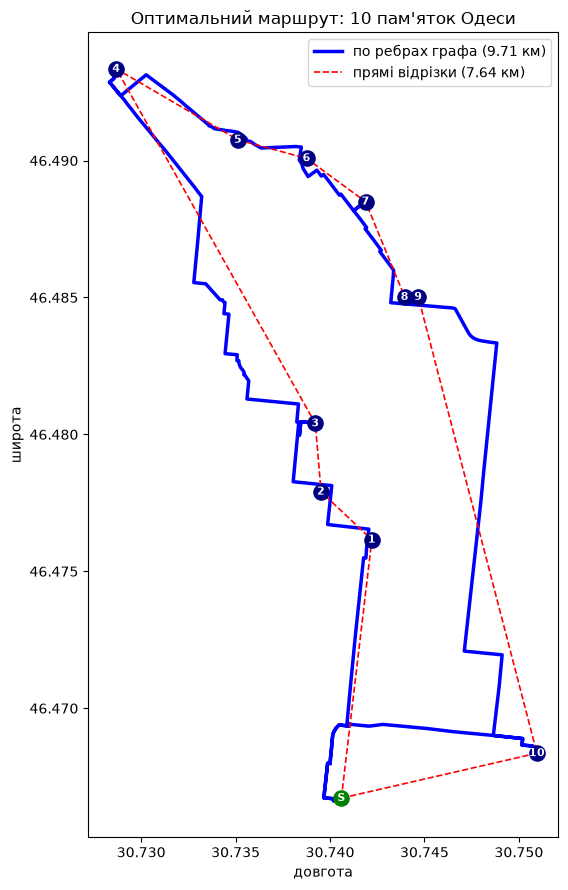

In [78]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

tour = ex10                                    # оптимальний маршрут (Held–Karp)
road_line = route_coords(tour, ids10)          # лінія по ребрах графа
straight_line = [(pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]) for i in tour]   # прямі відрізки

L_road = tour_length(D10, tour)
L_straight = tour_length(E10, tour)
print('по ребрах графа : %.2f км' % (L_road / 1000))
print('прямими лініями : %.2f км' % (L_straight / 1000))
print('різниця         : %.2f км (у %.2f раза довше)' % ((L_road - L_straight) / 1000, L_road / L_straight))

c = pts10.geometry.unary_union.centroid
fmap = folium.Map(location=[c.y, c.x], zoom_start=15, tiles=BASEMAP)

folium.PolyLine(road_line, color='blue', weight=5, opacity=0.8,
                tooltip='маршрут по вулицях: %.2f км' % (L_road / 1000)).add_to(fmap)
folium.PolyLine(straight_line, color='red', weight=2, dash_array='8',
                tooltip='прямі відрізки: %.2f км' % (L_straight / 1000)).add_to(fmap)

for step, i in enumerate(tour[:-1]):
    lat, lon = pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]
    label = 'S' if i == 0 else str(step)
    folium.Marker(
        [lat, lon], tooltip='%s. %s' % (label, pts10['name'].iloc[i]),
        icon=folium.DivIcon(html='<div style="background:%s;color:white;border-radius:50%%;'
                                 'width:24px;height:24px;text-align:center;line-height:24px;'
                                 'font-weight:bold;border:2px solid white">%s</div>'
                                 % ('green' if i == 0 else 'navy', label))
    ).add_to(fmap)

fmap.save('lr5_маршрут.html')
print('збережено lr5_маршрут.html')

# статична копія, щоб карту було видно в зошиті
fig, ax = plt.subplots(figsize=(9, 9))
ry, rx = zip(*road_line); sy, sx = zip(*straight_line)
ax.plot(rx, ry, color='blue', lw=2.5, label='по ребрах графа (%.2f км)' % (L_road / 1000))
ax.plot(sx, sy, color='red', lw=1.2, ls='--', label='прямі відрізки (%.2f км)' % (L_straight / 1000))
for step, i in enumerate(tour[:-1]):
    x, y = pts10.geometry.x.iloc[i], pts10.geometry.y.iloc[i]
    ax.scatter(x, y, s=120, color='green' if i == 0 else 'navy', zorder=3)
    ax.annotate('S' if i == 0 else str(step), (x, y), color='white', ha='center', va='center',
                fontsize=8, fontweight='bold', zorder=4)
ax.set_title('Оптимальний маршрут: 10 пам\'яток Одеси'); ax.legend(); ax.set_aspect(1.45)
ax.set_xlabel('довгота'); ax.set_ylabel('широта')
plt.tight_layout(); plt.show()

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [79]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.5 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [80]:
REPORT = '''
Місто: Одеса (варіант 4). Основний сервер overpass-api.de відхиляв автоматизовані
запити («public endpoint is intended for browser-based tools»), дзеркала не відповідали,
тому сирі дані завантажено вручну через Overpass Turbo у форматі OSM XML (ті самі
фільтри тегів, що й у osmnx), а далі оброблено osmnx (features_from_xml, graph_from_xml).

Завдання 1.2. Перше читання сирих файлів OSM: передано мережею 12.5 МБ (пам'ятки
1.18 МБ + пішохідна мережа 11.35 МБ), обробка мережі — 16.7 с, шару пам'яток — 1.6 с.
Повторний запуск читає знімки GeoParquet: передано 0 МБ, мережа — […] с, тобто
у […] разів швидше; знімки займають 5.0 МБ проти 12.5 МБ сирого XML.

1. Відкинуто 348 об'єктів з 895 (39 %): за тегами (historic=* або tourism з переліку)
   пройшли всі 895, бо саме за цими тегами дані й завантажувались; відкинуто об'єкти
   без name — найбільше historic=heritage (163: позначки «пам'ятка архітектури» на
   безіменних будинках), безіменні memorial (74, переважно меморіальні дошки),
   artwork (56) і attraction (36). Лишилось 547 кандидатів (343 точки, 199 полігонів,
   5 ліній). На кроці 3.3 вилучено ще 3: вокзал (це старт маршруту), дубль художнього
   музею і демонтований пам'ятник. Віддати фільтр замовнику без пояснень не можна:
   правило «є назва» відкидає 39 % об'єктів, серед яких можуть бути цінні будівлі,
   а частина важливих місць (театри з тегом лише amenity=theatre) у вибірку не
   потрапляє взагалі.

2. Рейтинг: score = 0.40·wiki + 0.25·rank(n_lang) + 0.15·museum/gallery
   + 0.10·historic + 0.10·rank(площа). wiki має найбільшу вагу, бо це незалежне
   визнання: хтось сторонній написав про об'єкт статтю. Кількість перекладів назви
   (rank, бо величина неперервна) — друга: перекладають те, що шукають туристи.
   Музей/галерея — місце, призначене для відвідування. historic має малу вагу, бо
   він є майже в усіх кандидатів і мало розрізняє. Площа — найслабший сигнал
   (великим буває і склад). Неперервні ознаки зведено до спільної шкали 0..1 через
   rank(pct=True), ваги в сумі дають 1.

3. Збіглися 2 з 10 (вокзал і театр музичної комедії). За площею в десятку потрапили
   «Ангари», «Ангари депо», «Тюремний замок» і монастир на цілий квартал, тобто
   великі, але не туристичні об'єкти. Обидва списки отримано з тих самих даних без
   жодної помилки, тож «найкращі» — це не властивість даних, а наслідок обраного
   критерію; критерій треба явно називати й захищати. Водночас і наш критерій має
   вади: Оперний театр (tourism=attraction) у десятку не потрапив, бо йому бракує
   сигналів у тегах OSM, хоча для туриста він один із головних об'єктів.

4. Коефіцієнт обходу 1.22 для 11 точок і 1.26 для 31 точки — типовий для пішохідної
   мережі (1.2–1.6). Він близький до 4/π ≈ 1.27 — теоретичного середнього обходу для
   ідеальної прямокутної сітки вулиць, а центр Одеси саме такий (регулярні квартали).
   Асиметрія 0 м: для пішохода односторонній рух не діє (граф двонапрямлений).
   Недосяжних пар немає. Довжина оптимального маршруту по вулицях 9.71 км проти
   7.64 км прямими лініями, тобто на 2.07 км (у 1.27 раза) більше.

5. Найближчий сусід гірший за точний розв'язок на 7.54 % (10.44 км проти 9.71 км,
   ≈730 м зайвої ходьби), 2-opt — лише на 1.30 % (≈130 м). На 30 точках 2-opt
   скоротив маршрут найближчого сусіда на 15.9 % (27.94 → 23.49 км) за 0.01 с. Отже,
   помилка жадібного методу зростає з кількістю точок: він обирає найближче зараз
   і змушений наприкінці робити довгі переходи назад, а 2-opt це виправляє.

6. Таблиця Held–Karp має 2^(n−1)·(n−1) клітин. Для 31 точки (30 пам'яток + вокзал)
   це 2^30·30 ≈ 32.2 млрд клітин ≈ 258 ГБ лише на числа по 8 байтів (у реалізації на
   списках Python — у кілька разів більше), тоді як ноутбук має 8–16 ГБ оперативної
   пам'яті. Заважає саме обсяг пам'яті: таблиця не поміщається, навіть якби часу було
   вдосталь. Операцій при цьому ≈ 9.7·10^11, що в чистому Python — дні роботи. Для
   порівняння: 11 точок — 10 240 клітин, 26 точок — уже 6.7 ГБ.

7. Що виявилось неправильним у даних:
   • 348 об'єктів без назви — відкинуто (п. 1).
   • Дубль: «Одеський національний художній музей» (museum) і «Одеський художній
     музей» (gallery) за 21 м — той самий музей двічі; залишено перший (вищий score).
   • «Пам'ятник засновникам Одеси (демонтований)» за 22–26 м від музею: пам'ятник
     демонтовано й перенесено на територію музею — вилучено.
   • Залізничний вокзал серед пам'яток (historic=heritage + tourism=attraction) —
     вилучено, бо він є стартом маршруту.
   • Пари Будинок Руссова — Будинок Лібмана (42 м) і Літературний — Археологічний
     музей (55 м) — різні об'єкти, залишено.
   • На спрощеному графі (simplify=True) Літературний і Археологічний музеї сіли на
     один вузол (11 точок → 10 вузлів), і матриця дала б між ними 0 м. Граф
     перебудовано без спрощення (simplify=False): 11 точок → 11 вузлів.
   • Висновок, якого не було в завданні: найщільніші комірки H3 (23–24 об'єкти) лежать
     не в історичному центрі, а на півдні міста, біля меморіалу 411-ї батареї, де кожна
     гармата, танк і літак картографовані окремим об'єктом. Щільність об'єктів OSM
     відображає детальність картографування, а не цінність місця. Водночас половина
     всіх 547 пам'яток зосереджена у 34 з 219 непорожніх комірок (15.5 %), тобто в
     центрі біля порту, тому маршрут компактний, а помітну частку його довжини
     становить шлях від вокзалу до центру й назад.
   • Біля кожної точки маршруту є заклад (кафе, ресторан, туалет) у межах 23–119 м.

Декларація про використання ШІ:
Використано Claude (Anthropic) як помічника: код завдань 1.1, 2.1, 3.1–3.3, 4, 4.1,
5.1, 6.1, 6.2, 7.1, 8.1, 9.1; поради щодо обходу блокування Overpass (ручне
завантаження через Overpass Turbo та читання OSM XML); виявлення злипання точок на
спрощеному графі; чернетка звіту. Перевірено самостійно: ноутбук виконується від
початку до кінця; виконано всі вбудовані самоперевірки (структура маршрутів, 2-opt
не гірший за найближчого сусіда, точний розв'язок не гірший за наближені);
коефіцієнт обходу звірено з контрольним діапазоном 1.2–1.6; розташування пам'яток,
шестикутників H3 і маршруту перевірено візуально на картах; рішення щодо дублікатів
ухвалено після перегляду назв і відстаней.
'''
print(REPORT)


Місто: Одеса (варіант 4). Основний сервер overpass-api.de відхиляв автоматизовані
запити («public endpoint is intended for browser-based tools»), дзеркала не відповідали,
тому сирі дані завантажено вручну через Overpass Turbo у форматі OSM XML (ті самі
фільтри тегів, що й у osmnx), а далі оброблено osmnx (features_from_xml, graph_from_xml).

Завдання 1.2. Перше читання сирих файлів OSM: передано мережею 12.5 МБ (пам'ятки
1.18 МБ + пішохідна мережа 11.35 МБ), обробка мережі — 16.7 с, шару пам'яток — 1.6 с.
Повторний запуск читає знімки GeoParquet: передано 0 МБ, мережа — […] с, тобто
у […] разів швидше; знімки займають 5.0 МБ проти 12.5 МБ сирого XML.

1. Відкинуто 348 об'єктів з 895 (39 %): за тегами (historic=* або tourism з переліку)
   пройшли всі 895, бо саме за цими тегами дані й завантажувались; відкинуто об'єкти
   без name — найбільше historic=heritage (163: позначки «пам'ятка архітектури» на
   безіменних будинках), безіменні memorial (74, переважно меморіальні дошки),
   art